In [1]:
import sys
# Append the previous directory to the path
sys.path.append('../')

In [2]:
import numpy as np
import pandas as pd
from exp_utils import CounterPlotNice
from sklearn.ensemble import RandomForestClassifier

In [3]:
# Download wine dataset
! wget https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv

# Read wine dataset
wine = pd.read_csv('winequality-red.csv', sep=';')

X, y = wine.drop('quality', axis=1), wine['quality']

# Transform X to numpy
X  = X.to_numpy()
# Transform y to binary
y = np.where(y > 5, 1, 0)

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [4]:
# Make RF model for noisy dataset
model = RandomForestClassifier(random_state=42)

In [5]:
model.fit(X, y)

RandomForestClassifier(random_state=42)

In [6]:
exp_nice = CounterPlotNice(
    predict_fn=model.predict_proba,
    X_train=X,
    y_train=y,
    cat_feat=[]
    )

In [100]:
X.shape

(1599, 11)

Todo: find a nice data representation so that i can plot the deviation across:
- instances
- sample sizes

In [ ]:
N_instance_samples = 100
large_D_CFE_idx = 553  # CFE with D = 7
n_instances, dim = X.shape

example_instance_idxs = np.random.choice(X.shape[0], N_instance_samples)
if large_D_CFE_idx not in example_instance_idxs: np.append(example_instance_idxs, large_D_CFE_idx)  # ensure the larger-dimensional CFE is in there
estimate_deviations = {}

for example_instance_idx in example_instance_idxs:
    # Real
    x_cs = exp_nice.explain(
        np.array([X[example_instance_idx]]),
        sample_size=None
        )
    countershapley_values = x_cs[0].countershapley_values()


    sample_sizes = np.arange(2, len(countershapley_values['feature_names']), 10)
    for j, sample_size in enumerate(sample_sizes):
        # Estimated CS values
        x_cs = exp_nice.explain(
            np.array([X[example_instance_idx]]),
            sample_size=sample_size
            )
        countershapley_estimates = x_cs[0].countershapley_values()
        for feat_name, estimate, real_val in zip(
            countershapley_estimates['feature_names'], 
            countershapley_estimates['feature_values'],
            countershapley_values['feature_values']
            ):
            if feat_name not in estimate_deviations: 
                estimate_deviations[feat_name] = {"sample_size": [],"cs_dev": []}
            dev = abs(estimate - real_val) / real_val
            estimate_deviations[feat_name]["sample_size"].append(sample_size)
            estimate_deviations[feat_name]["cs_dev"].append(dev)
            

Shape dont match, huh

In [114]:
estimate_deviations

{'f7': {'sample_size': [2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2],
  'cs_dev': [0.7671641791044777,
   0.7653061224489796,
   0.7933333333333333,
   0.8794326241134752,
   0.9748953974895397,
   0.9914285714285714,
   0.9520710059171598,
   0.5582822085889569,
   1.0727272727272728,
   0.7283950617283951,
   0.9080459770114941,
   0.5185185185185186,
   0.9714285714285715,
   0.8952380952380952,
   0.8090909090909091,
   0.7636363636363637,
   0.5210084033613445,
   0.38235294117647056,
   0.32323232323232326,
   0.8611111111111112,
   0.7534246575342466]},
 'f10': {'sample_size': [2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2,
   2],
  'cs_dev': [0.7154471544715446,
   0.7516629711751663,
   0.6349206349206349,
   0.4074074074074074,
   0.76,
   0.6499999999999999,
   0.9

Text(0.5, 0, 'Sample size (% of max)')

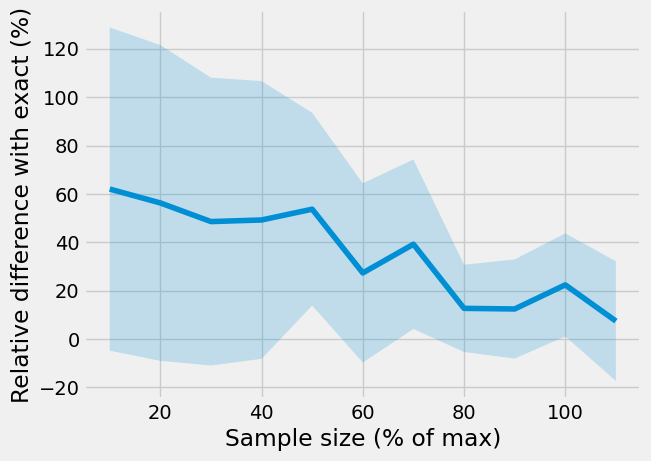

In [98]:
import matplotlib.pyplot as plt
plt.style.use("fivethirtyeight")

estimate_deviations_values = np.asarray(list(estimate_deviations.values()))
m, s = estimate_deviations_values.mean(axis=0), estimate_deviations_values.std(axis=0)

fig, ax = plt.subplots()
plt.plot(sample_sizes, 100*m)
plt.fill_between(sample_sizes, 100*(m-s), 100*(m+s), alpha=.2)

plt.ylabel("Relative difference with exact (%)")
plt.xlabel("Sample size (% of max)")